# DHVC 통계 시각화

`out_1e5`, `out_1e6`, `out_1e7` 디렉터리의 출력을 시각화한다.

- **`monitor.csv`** — 스텝별 시계열 진단 (`Re_dstar`, `Nu`, `KE`, `theta_rms`, `dt`, `div` ...). 수렴/안정성 모니터링용.
- **`stats_*.dat`** — Tecplot POINT 포맷 벽면수직(Z) 통계 프로파일 (`U_mean`, `u_rms`, `uw_stress`, `P_mean` ...).

`out_*` 디렉터리를 자동 탐색하며, 열 구성이 다른 케이스(예: `out_1e7`는 `Re_dstar`까지만)도 자동 처리한다.
의존성: `numpy`, `matplotlib` (pandas 불필요).

In [1]:
import os, re, glob, csv
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

# 노트북이 위치한 apps/dhvc 디렉터리. 절대경로 우선, 없으면 현재 작업 디렉터리.
APP_DIR = '/shared/home/wel1come1234/workspace/MPM-STD_C/apps/dhvc'
if not os.path.isdir(os.path.join(APP_DIR, 'out_1e5')):
    APP_DIR = os.getcwd()
print('APP_DIR =', APP_DIR)

APP_DIR = /scratch/x3319a05/MPM-STD_C/apps/dhvc


In [2]:
def parse_monitor(path):
    """monitor.csv -> {column_name: np.ndarray}. 헤더의 열 구성을 그대로 따른다."""
    with open(path) as f:
        reader = csv.reader(f)
        header = next(reader)
        rows = [[float(x) for x in r] for r in reader if r]
    arr = np.array(rows)
    return {name: arr[:, i] for i, name in enumerate(header)}


def parse_stats(path):
    """Tecplot POINT 포맷 stats_*.dat -> dict(step, n, vars, data={var: ndarray})."""
    step = n = None
    var_names = []
    n_head = 0
    with open(path) as f:
        for line in f:
            s = line.strip()
            if s.startswith('TITLE'):
                m = re.search(r'step=(\d+).*?n=(\d+)', s)
                if m:
                    step, n = int(m.group(1)), int(m.group(2))
                n_head += 1
            elif s.startswith('VARIABLES'):
                var_names = re.findall(r'"([^"]+)"', s)
                n_head += 1
            elif s.startswith('ZONE'):
                n_head += 1
            else:
                break
    data = np.loadtxt(path, skiprows=n_head)
    cols = {name: data[:, i] for i, name in enumerate(var_names)}
    return {'step': step, 'n': n, 'vars': var_names, 'data': cols}


def parse_log(path):
    """GPU 로그(dhvc_gpu_*.log)에서 step, t, 순간 Re, avg(누적 Re_dstar) 추출.
    포맷 A:  step=100 ... Re=76.746(avg=0.000) ...
    포맷 B:  step=100 ... Re_dstar=0.000 (target~20.976)   (1e7)"""
    rx_step = re.compile(r'step=(\d+)')
    rx_t    = re.compile(r't=([-\d.eE+]+)')
    rx_re   = re.compile(r'\bRe=([-\d.eE+]+)')        # 순간 Re (포맷 A)
    rx_red  = re.compile(r'Re_dstar=([-\d.eE+]+)')    # 포맷 B
    rx_avg  = re.compile(r'avg=([-\d.eE+]+)')
    step, t, re_inst, avg = [], [], [], []
    with open(path) as f:
        for line in f:
            ms = rx_step.search(line)
            if not ms:
                continue
            mt, mre, mred, mavg = (rx_t.search(line), rx_re.search(line),
                                   rx_red.search(line), rx_avg.search(line))
            step.append(int(ms.group(1)))
            t.append(float(mt.group(1)) if mt else np.nan)
            m = mre or mred
            re_inst.append(float(m.group(1)) if m else np.nan)
            avg.append(float(mavg.group(1)) if mavg else np.nan)
    return {'step': np.array(step), 't': np.array(t, float),
            'Re': np.array(re_inst, float), 'avg': np.array(avg, float)}

In [3]:
# out_* 케이스 자동 탐색 및 로드
case_dirs = sorted(glob.glob(os.path.join(APP_DIR, 'out_*')))

cases = {}
for d in case_dirs:
    label = os.path.basename(d).replace('out_', '')          # 'out_1e5' -> '1e5'
    mon_path = os.path.join(d, 'monitor.csv')
    monitor = parse_monitor(mon_path) if os.path.exists(mon_path) else None

    # 파일명: 구형 stats_<step>.dat, 신형 stats_t<time>.dat 모두 지원
    def _stat_key(p):
        m = re.search(r'stats_t?(\d+)', os.path.basename(p))
        return int(m.group(1)) if m else -1
    stats_files = sorted(glob.glob(os.path.join(d, 'stats_*.dat')), key=_stat_key)
    stats = []
    for p in stats_files:
        s = parse_stats(p)
        s['file'] = os.path.basename(p)
        s['tag'] = s['file'].replace('stats_', '').replace('.dat', '')  # 't270' 또는 '20000'
        stats.append(s)

    log_path = os.path.join(APP_DIR, 'logs', f'dhvc_gpu_{label}.log')
    log = parse_log(log_path) if os.path.exists(log_path) else None

    cases[label] = {'dir': d, 'monitor': monitor, 'stats': stats, 'log': log}
    nrows = len(monitor['step']) if monitor else 0
    cols = list(monitor) if monitor else []
    steps = [s['step'] for s in stats]
    nlog = len(log['step']) if log else 0
    print(f"Ra={label:>4}  monitor: {nrows:>4} rows {cols}")
    print(f"          stats:   {len(stats)} file(s) at steps {steps}")
    print(f"          log:     {nlog:>4} rows (dhvc_gpu_{label}.log)")

Ra= 1e5  monitor:  308 rows ['step', 't', 'dt', 'div', 'Re_avg', 'Re_inst', 'KE', 'Nu', 'theta_rms', 'wall_s', 'ms_per_step']
          stats:   5 file(s) at steps [5582, 8052, 10533, 13078, 15443]
          log:        0 rows (dhvc_gpu_1e5.log)
Ra= 1e6  monitor:  346 rows ['step', 't', 'dt', 'div', 'Re_avg', 'Re_inst', 'KE', 'Nu', 'theta_rms', 'wall_s', 'ms_per_step']
          stats:   5 file(s) at steps [5864, 8584, 11543, 14334, 17318]
          log:        0 rows (dhvc_gpu_1e6.log)
Ra= 1e7  monitor: 1856 rows ['step', 't', 'dt', 'div', 'Re_avg', 'Re_inst', 'KE', 'Nu', 'theta_rms', 'wall_s', 'ms_per_step']
          stats:   11 file(s) at steps [15440, 23269, 31246, 38925, 46901, 54440, 62161, 69933, 77474, 85013, 92800]
          log:        0 rows (dhvc_gpu_1e7.log)
Ra= 1e8  monitor: 4421 rows ['step', 't', 'dt', 'div', 'Re_avg', 'Re_inst', 'KE', 'Nu', 'theta_rms', 'wall_s', 'ms_per_step']
          stats:   6 file(s) at steps [60007, 88460, 119300, 147747, 177561, 207071]
      

## 1. monitor.csv — 시계열 수렴 진단

Re 패널에는 `logs/dhvc_gpu_*.log` 의 **순간 Re** 를 반투명 파선으로 겹쳐 그린다
(실선 = monitor.csv 의 $Re_{\delta^*}$ 누적평균, 파선 = 로그 순간 Re).
순간 Re(~10–770)와 누적 $Re_{\delta^*}$(~5)를 함께 보기 위해 y축은 로그 스케일.

saved dhvc_monitor.png


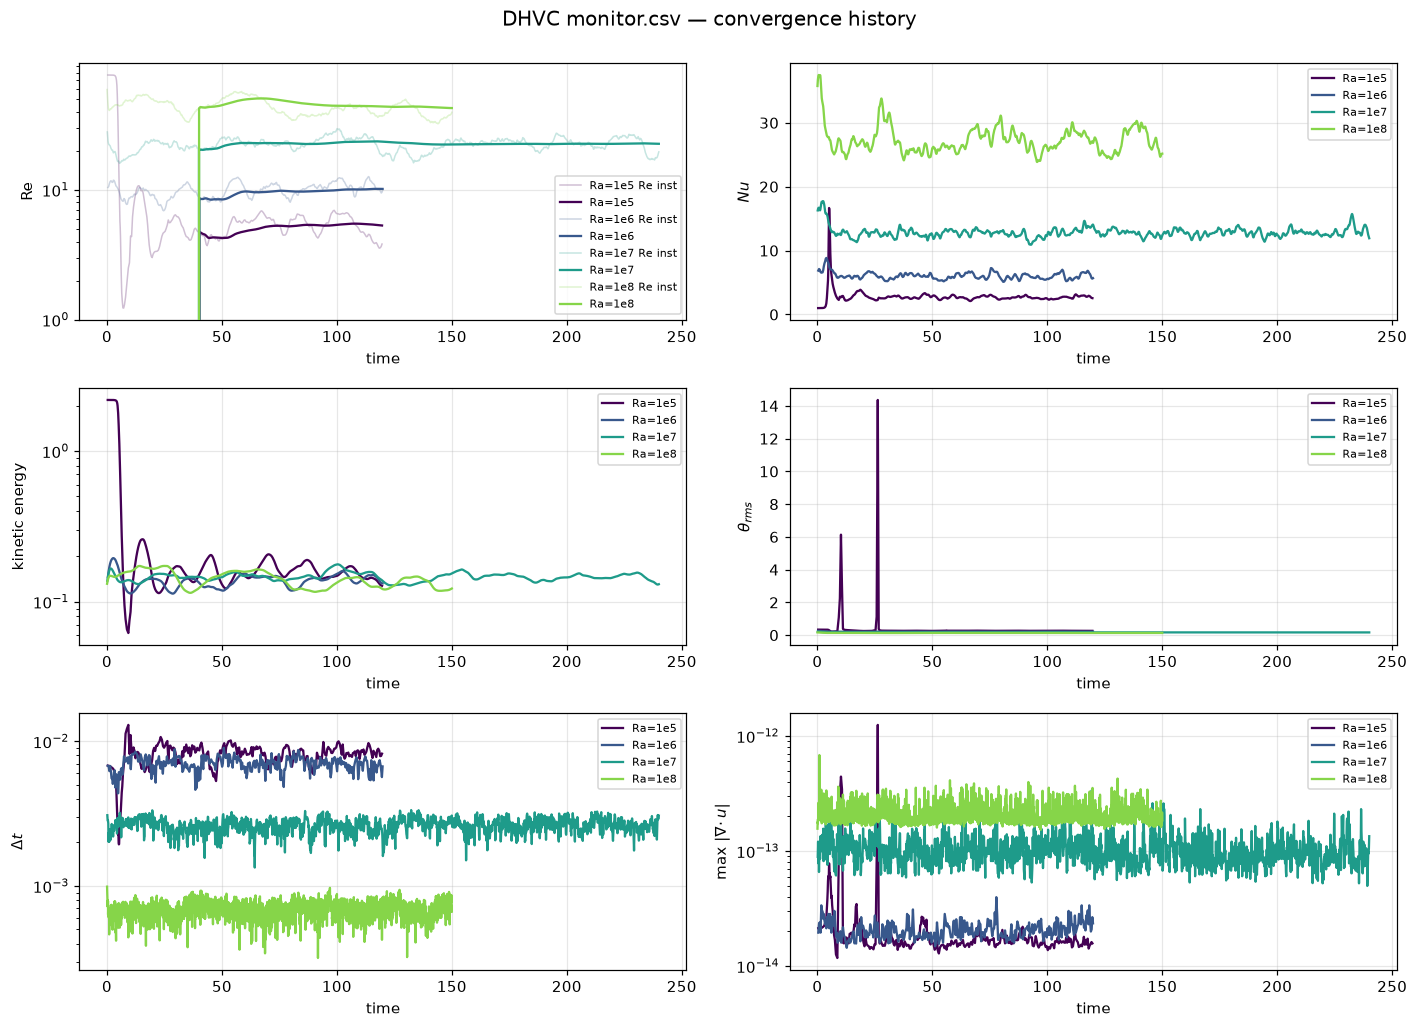

In [4]:
# 케이스별 색, x축은 물리시간 t (없으면 step)
colors = {lab: plt.cm.viridis(v) for lab, v in
          zip(cases, np.linspace(0.0, 0.82, len(cases)))}

# (열 이름, 표시 라벨, y-로그 여부)
quantities = [
    ('Re_avg',  r'$Re_{\delta^*}$',  False),
    ('Nu',        r'$Nu$',             False),
    ('KE',        'kinetic energy',    True),
    ('theta_rms', r'$\theta_{rms}$',   False),
    ('dt',        r'$\Delta t$',       True),
    ('div',       r'max $|\nabla\!\cdot u|$', True),
]

use_time = any('t' in (c['monitor'] or {}) for c in cases.values())
xlabel = 'time' if use_time else 'step'

ncols = 2
nrows = (len(quantities) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.1 * nrows))
axes = np.ravel(axes)

for ax, (key, ylabel, logy) in zip(axes, quantities):
    plotted = False
    for lab, c in cases.items():
        mon = c['monitor']
        if mon and key in mon:
            x = mon['t'] if 't' in mon else mon['step']
            # Re 패널: monitor.csv 의 순간 Re_inst 를 배경에 반투명으로 먼저 깔기
            if key == 'Re_avg' and 'Re_inst' in mon:
                ax.plot(x, mon['Re_inst'], color=colors[lab], lw=1.0,
                        alpha=0.25, zorder=1, label=f'Ra={lab} Re inst')
            ax.plot(x, mon[key], color=colors[lab], lw=1.5, zorder=3,
                    label=f'Ra={lab}')
            plotted = True

    # Re 패널: (있다면) 로그 파일의 순간 Re 도 파선으로 겹쳐 그림
    if key == 'Re_avg':
        for lab, c in cases.items():
            log = c.get('log')
            if log is not None and log['Re'].size and (log['Re'] > 0).any():
                xl = log['t'] if use_time else log['step']
                ax.plot(xl, log['Re'], color=colors[lab], lw=1.3, ls='--',
                        alpha=0.45, label=f'Ra={lab} Re inst (log)')
                plotted = True
        ax.set_yscale('log')              # 순간 Re(~10–770)와 Re_avg(~5)를 함께
        ylabel = 'Re'
    elif logy:
        ax.set_yscale('log')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if plotted:
        pass
        ax.legend(fontsize=7, ncol=1)

for ax in axes[len(quantities):]:
    ax.set_visible(False)

fig.suptitle('DHVC monitor.csv — convergence history', fontsize=13, y=1.0)
fig.tight_layout()
# fig.savefig(os.path.join(APP_DIR, 'dhvc_monitor.png'), dpi=130, bbox_inches='tight')
print('saved dhvc_monitor.png')
plt.show()

In [5]:
# 최종 누적 평균 Re_dstar — monitor.csv 마지막 행의 Re_dstar (누적 평균값)
print('=== 최종 누적 평균 Re_dstar ===')
for lab, c in cases.items():
    mon = c['monitor']
    if not (mon and 'Re_avg' in mon):
        print(f'  Ra={lab:>4}: monitor.csv 없음 / Re_dstar 열 없음')
        continue
    step = int(mon['step'][-1])
    t    = mon['t'][-1] if 't' in mon else float('nan')
    red  = mon['Re_avg'][-1]
    note = '  (아직 0 — 통계 누적 전/미발달)' if red == 0 else ''
    print(f'  Ra={lab:>4}: Re_dstar = {red:8.4f}   (step {step}, t={t:.4g}){note}')

=== 최종 누적 평균 Re_dstar ===
  Ra= 1e5: Re_dstar =   5.3159   (step 15400, t=119.6)
  Ra= 1e6: Re_dstar =  10.1698   (step 17300, t=119.9)
  Ra= 1e7: Re_dstar =  22.6463   (step 92800, t=240)
  Ra= 1e8: Re_dstar =  42.6907   (step 221050, t=150)


## 2. stats_*.dat — 벽면수직 프로파일 (케이스별)

각 케이스에 대해 저장된 모든 통계 스텝을 한 그림에 겹쳐 그려 통계 수렴 정도를 확인한다.

saved dhvc_profiles_1e5.png


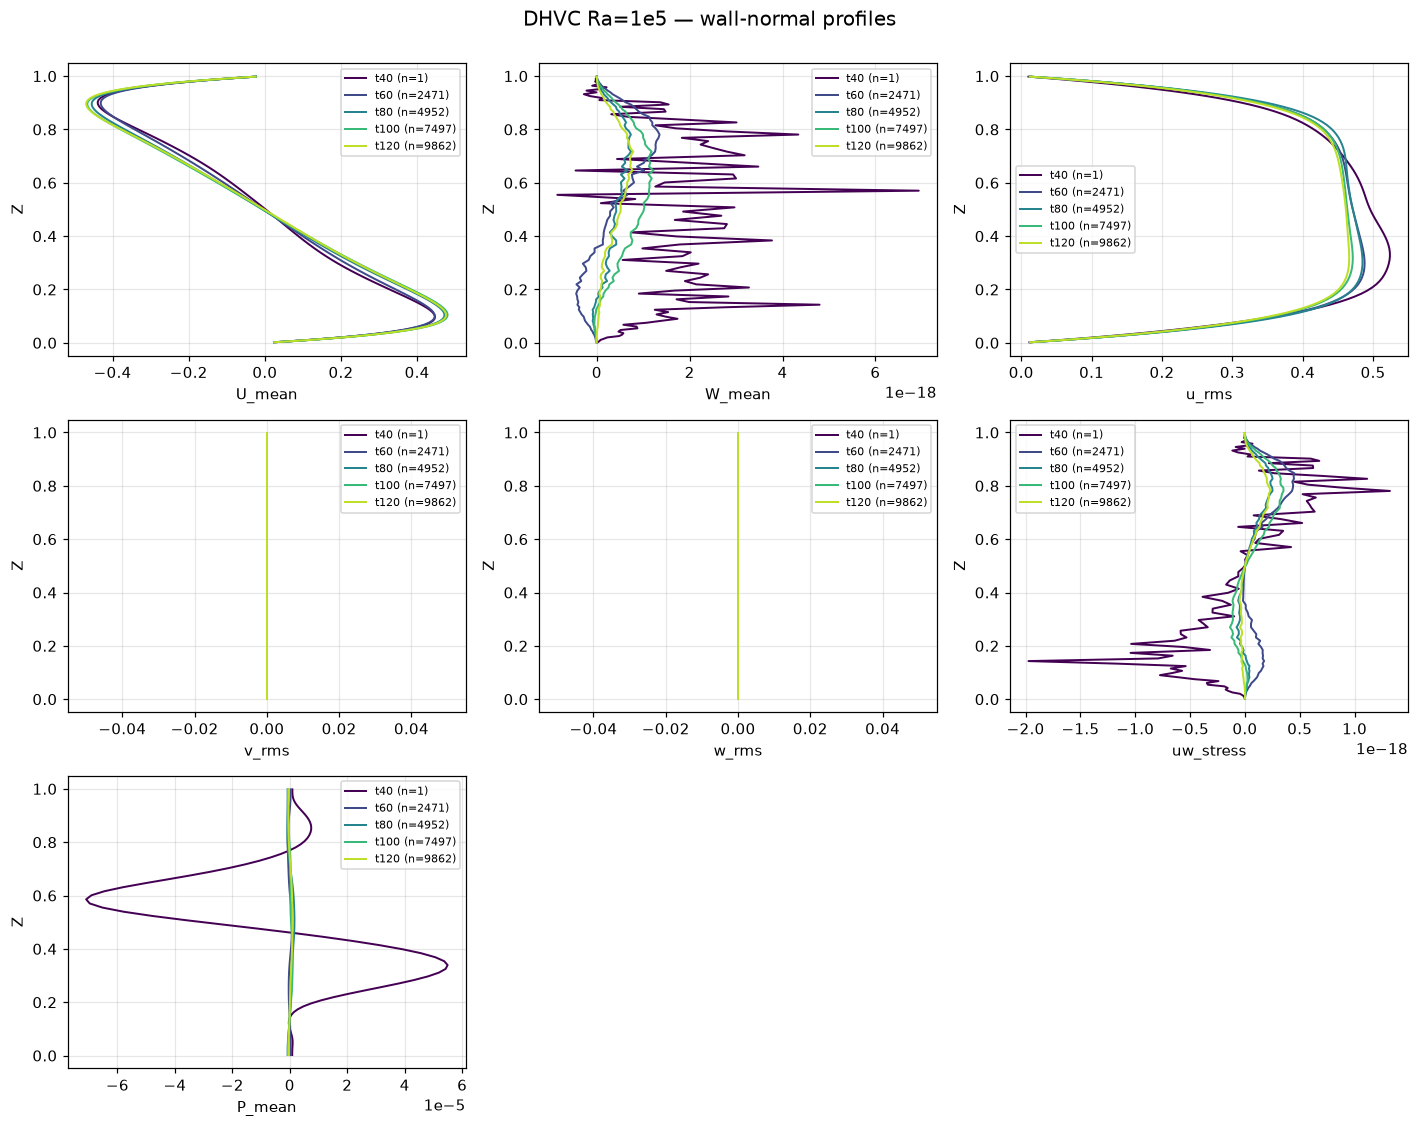

saved dhvc_profiles_1e6.png


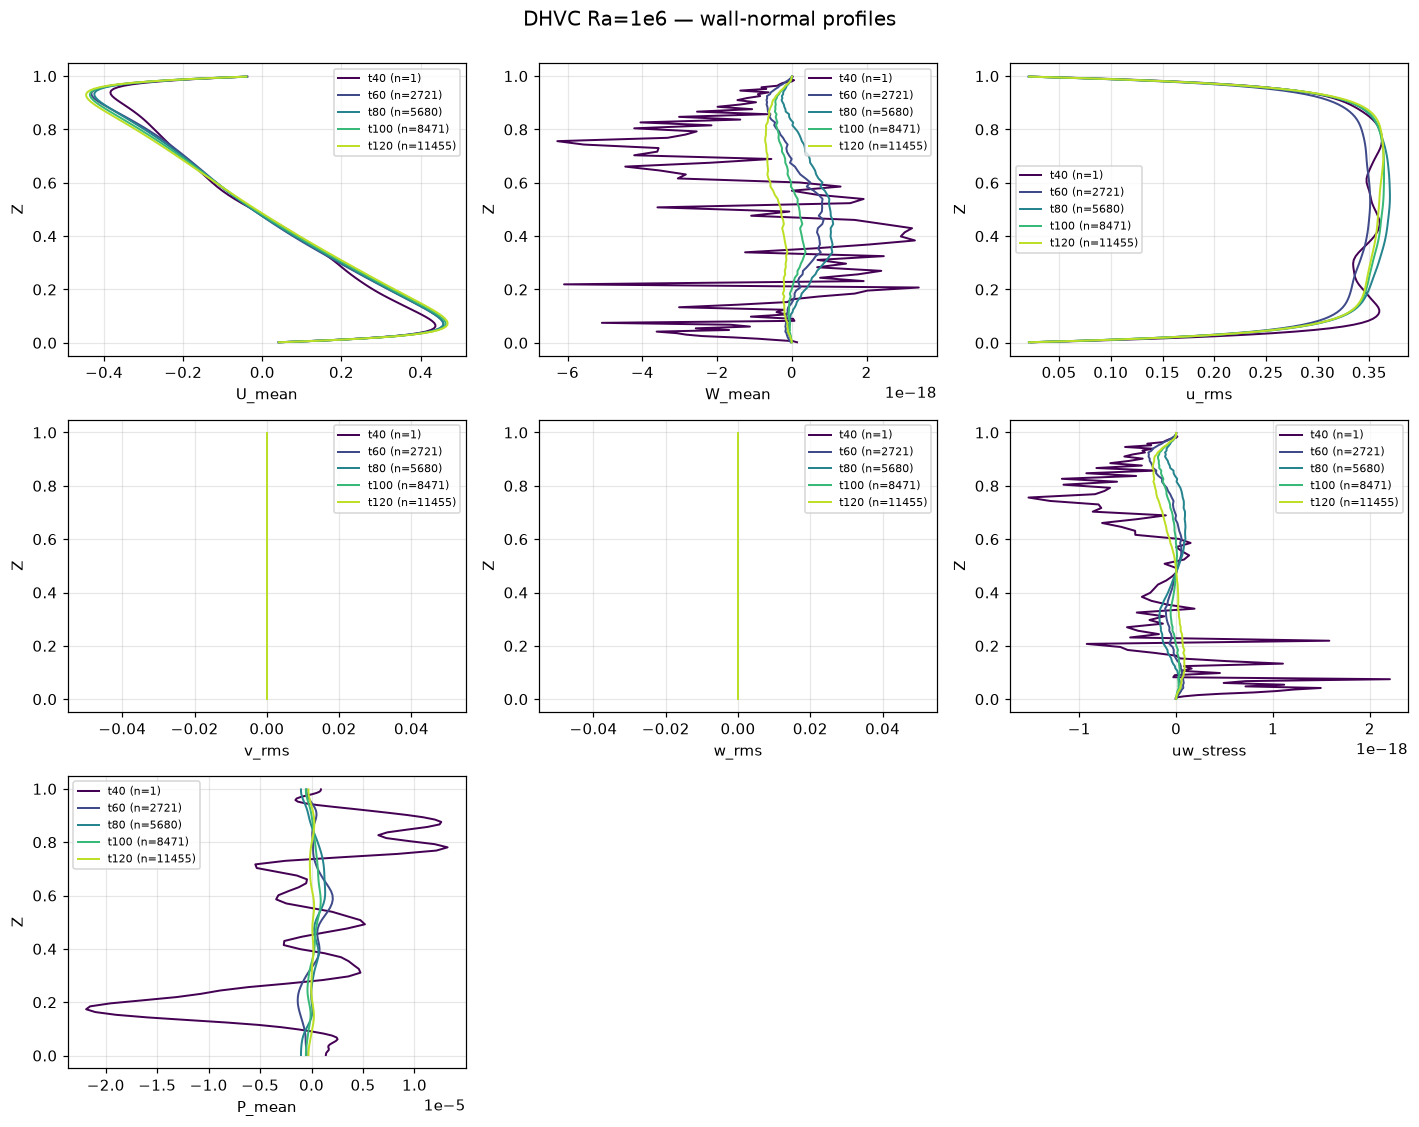

saved dhvc_profiles_1e7.png


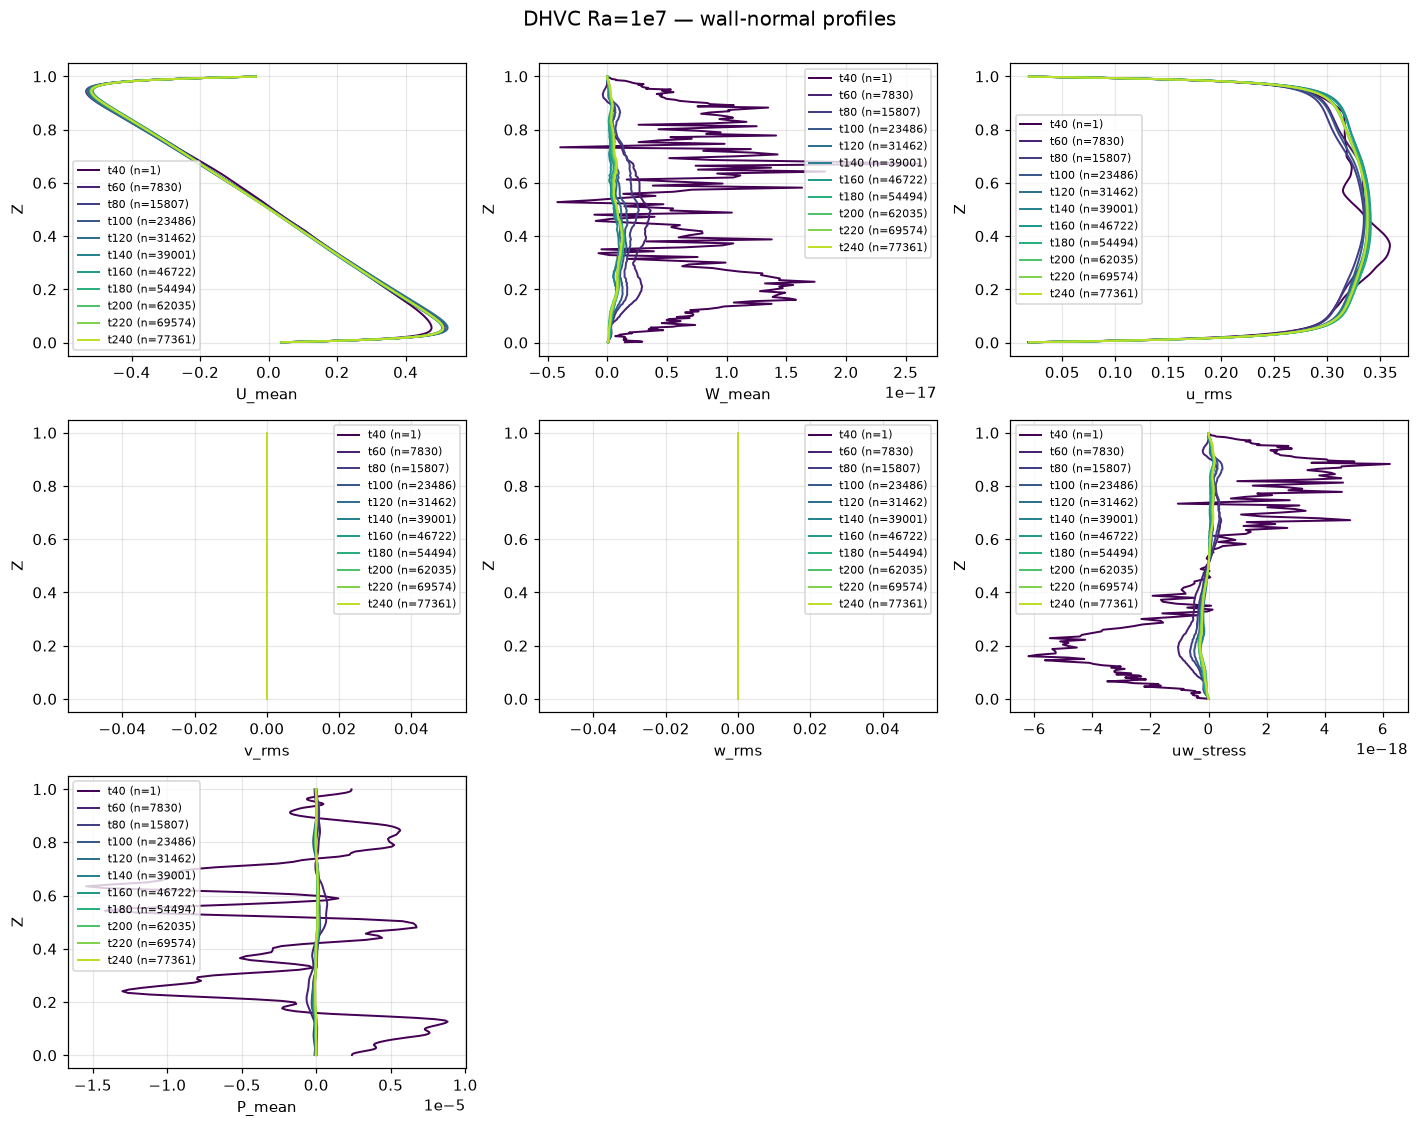

saved dhvc_profiles_1e8.png


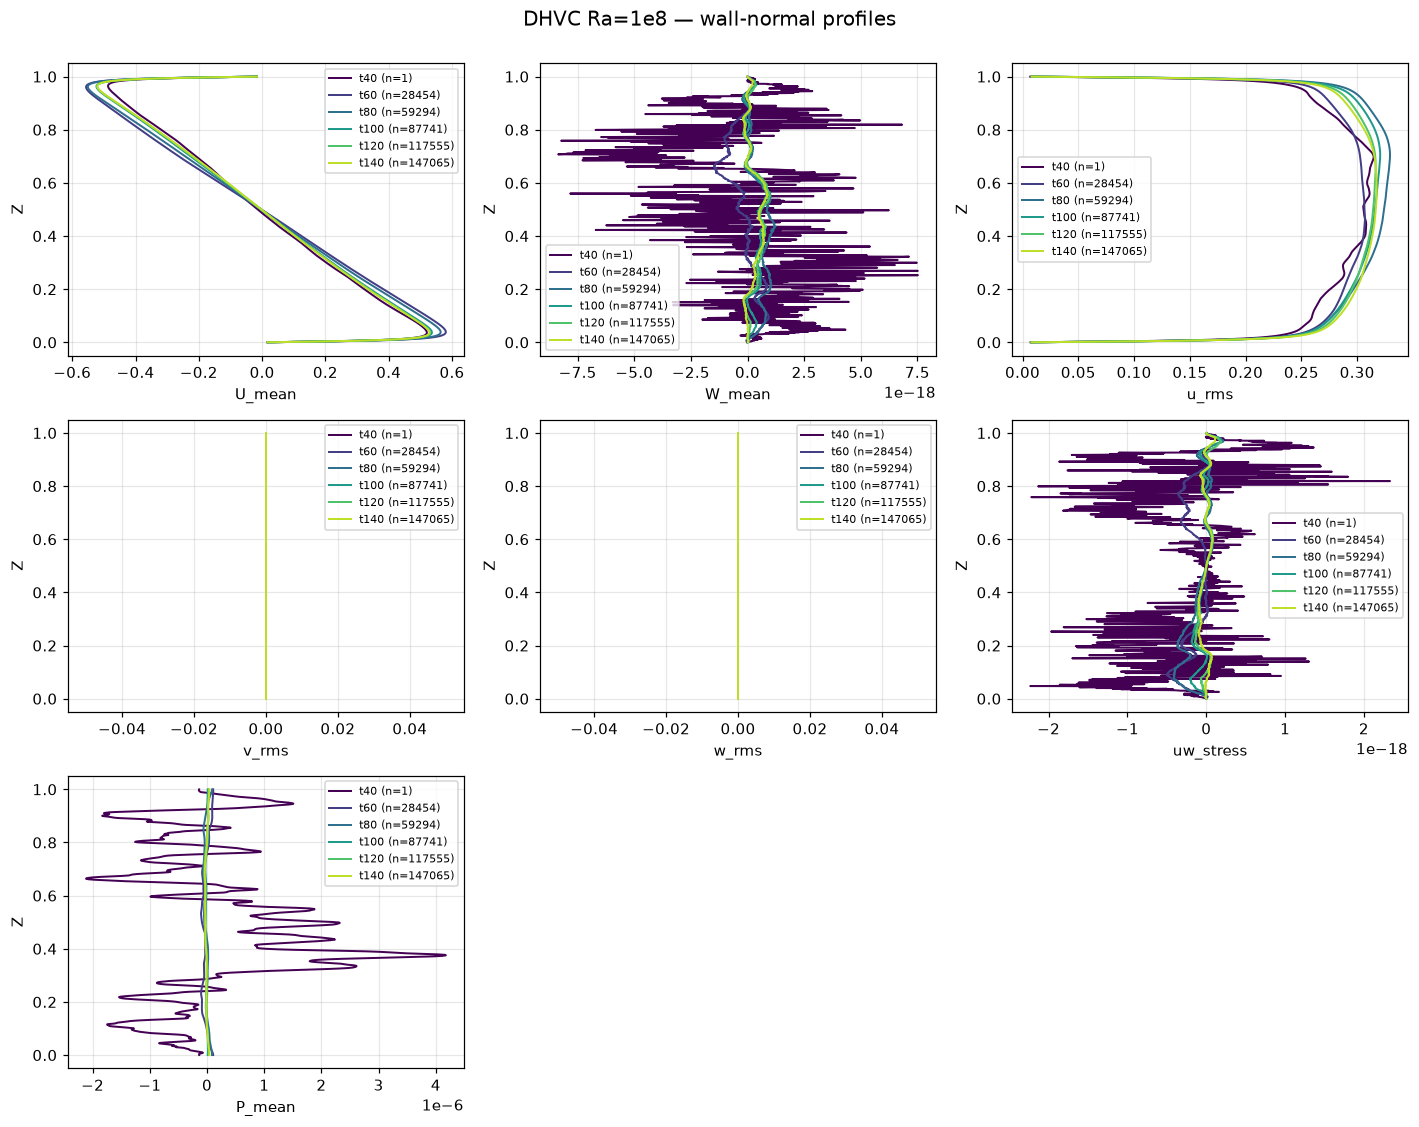

In [6]:
def plot_case_profiles(label, stats_list):
    if not stats_list:
        print(f'Ra={label}: stats 파일 없음 — 건너뜀')
        return
    var_names = stats_list[-1]['vars']
    profile_vars = [v for v in var_names if v not in ('Z', 'Z_plus')]
    n = len(profile_vars)
    ncols = 3
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.4 * nrows))
    axes = np.ravel(axes)

    tcolors = plt.cm.viridis(np.linspace(0, 0.9, len(stats_list)))
    for ax, v in zip(axes, profile_vars):
        for s, tc in zip(stats_list, tcolors):
            Z = s['data']['Z']
            tag = s.get('tag', f"step {s['step']}")
            ax.plot(s['data'][v], Z, lw=1.3, color=tc,
                    label=f"{tag} (n={s['n']})")
        ax.set_xlabel(v)
        ax.set_ylabel('Z')
        ax.legend(fontsize=7)
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle(f'DHVC Ra={label} — wall-normal profiles', fontsize=13, y=1.0)
    fig.tight_layout()
    # fig.savefig(os.path.join(APP_DIR, f'dhvc_profiles_{label}.png'),
    #                 dpi=130, bbox_inches='tight')
    print(f'saved dhvc_profiles_{label}.png')
    plt.show()


for label, c in cases.items():
    plot_case_profiles(label, c['stats'])

## 3. Ra 비교 — 최신 통계 프로파일

케이스마다 가장 최근(가장 많은 샘플) stats 파일을 골라 주요 프로파일을 비교한다.

saved dhvc_compare_Ra.png


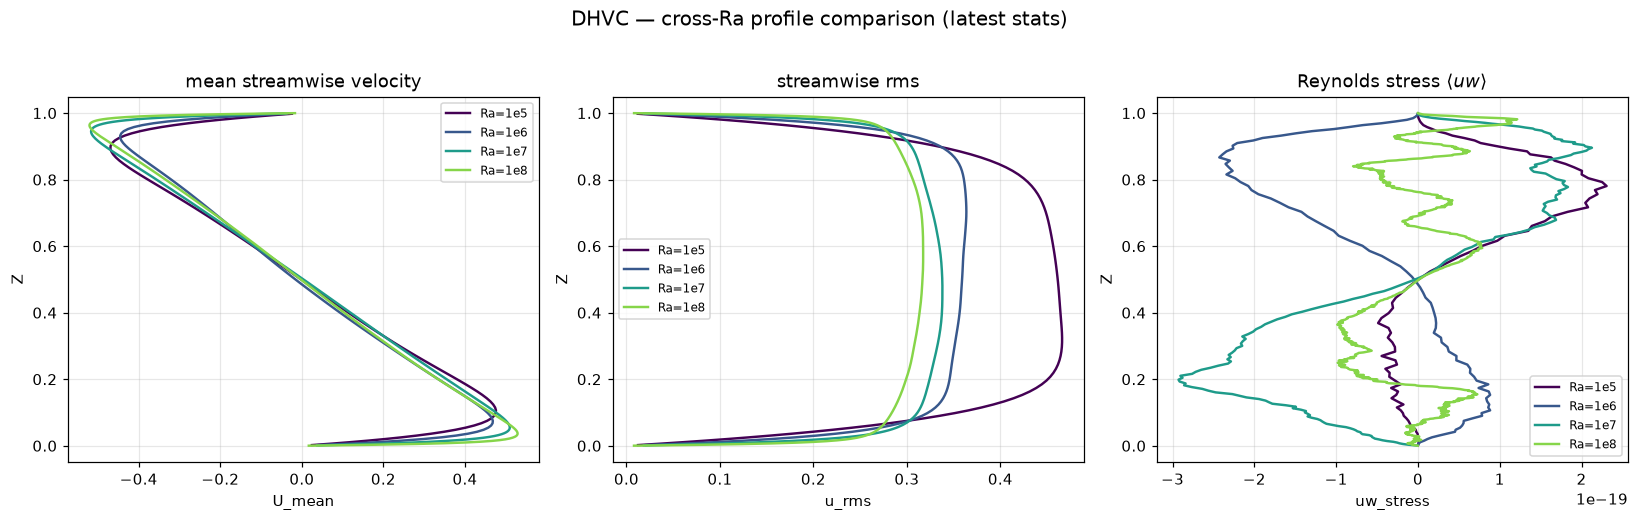

In [7]:
compare_vars = [('U_mean', 'mean streamwise velocity'),
                ('u_rms',  'streamwise rms'),
                ('uw_stress', r'Reynolds stress $\langle uw\rangle$')]

fig, axes = plt.subplots(1, len(compare_vars), figsize=(5 * len(compare_vars), 4.6))
axes = np.ravel(axes)

for ax, (v, title) in zip(axes, compare_vars):
    for lab, c in cases.items():
        if not c['stats']:
            continue
        s = c['stats'][-1]
        if v in s['data']:
            ax.plot(s['data'][v], s['data']['Z'], color=colors[lab],
                    lw=1.6, label=f'Ra={lab}')
    ax.set_xlabel(v)
    ax.set_ylabel('Z')
    ax.set_title(title)
    ax.legend(fontsize=8)

fig.suptitle('DHVC — cross-Ra profile comparison (latest stats)', fontsize=13, y=1.02)
fig.tight_layout()
# fig.savefig(os.path.join(APP_DIR, 'dhvc_compare_Ra.png'), dpi=130, bbox_inches='tight')
print('saved dhvc_compare_Ra.png')
plt.show()

## 4. Ra vs Re_dstar — 검증

각 케이스의 **최종 누적 평균 Re_dstar**(§1 마지막 값)를 Ra에 대해 그리고,
`PaScaL_TCS.csv` 참조 DNS 및 Ng et al. (2015) 상관식 $0.23\,Ra^{0.28}$ 과 비교한다.
아직 발달하지 않아 Re_dstar=0 인 케이스(예: 1e7)는 제외한다.

saved dhvc_Ra_vs_Redstar.png
=== Re_dstar 오차 (PaScaL_TCS / Ng et al. 상관식 대비) ===
  Ra=1e+05: Re_avg=5.3159  | PaScaL 5.378 (-1.1%)  | Ng 5.777 (-8.0%)
  Ra=1e+06: Re_avg=10.1698  | PaScaL 10.430 (-2.5%)  | Ng 11.008 (-7.6%)
  Ra=1e+07: Re_avg=22.6463  | PaScaL 22.947 (-1.3%)  | Ng 20.976 (+8.0%)
  Ra=1e+08: Re_avg=42.6907  | PaScaL 43.122 (-1.0%)  | Ng 39.969 (+6.8%)


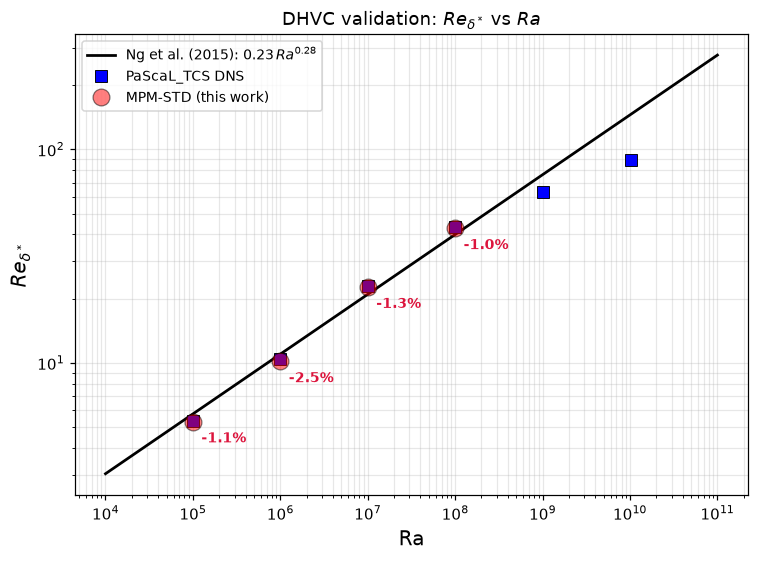

In [8]:
# (1) PaScaL_TCS 참조 DNS 로드  (Ra, Re_dstar)
csv_path = os.path.join(APP_DIR, 'PaScaL_TCS.csv')
pas_ra, pas_re = [], []
if os.path.exists(csv_path):
    with open(csv_path) as f:
        for line in f:
            parts = line.split(',')
            if len(parts) == 2:
                try:
                    pas_ra.append(float(parts[0]))
                    pas_re.append(float(parts[1]))
                except ValueError:
                    pass
pas_ra, pas_re = np.array(pas_ra), np.array(pas_re)

# (2) 이번 작업: 케이스별 최종 누적 Re_dstar ( > 0 만 )
work_ra, work_re = [], []
for lab, c in cases.items():
    mon = c['monitor']
    if mon and 'Re_avg' in mon and mon['Re_avg'][-1] > 0:
        try:
            work_ra.append(float(lab))           # '1e5' -> 1e5
        except:
            continue
        work_re.append(mon['Re_avg'][-1])
work_ra, work_re = np.array(work_ra), np.array(work_re)

# (3) Ng et al. (2015) 상관식
ra_line = np.logspace(4, 11, 400)
re_ng = 0.23 * ra_line**0.28

# (4) 플롯
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.loglog(ra_line, re_ng, 'k-', lw=1.8,
          label=r'Ng et al. (2015): $0.23\,Ra^{0.28}$')
if pas_ra.size:
    ax.loglog(pas_ra, pas_re, 'bs', ms=8, mec='k', mew=0.6,
              zorder=4, label='PaScaL_TCS DNS')
ax.loglog(work_ra, work_re, 'ro', ms=11, mec='k', mew=0.8, alpha=0.5,
          zorder=5, label='MPM-STD (this work)')

# PaScaL 참조 대비 오차(%) 주석 — 가장 가까운 Ra 매칭
for ra, re in zip(work_ra, work_re):
    if pas_ra.size:
        j = int(np.argmin(np.abs(np.log10(pas_ra) - np.log10(ra))))
        err = (re - pas_re[j]) / pas_re[j] * 100.0
        ax.annotate(f'{err:+.1f}%', xy=(ra, re), xytext=(ra * 1.25, re * 0.80),
                    fontsize=9, color='crimson', fontweight='bold')

ax.set_xlabel('Ra', fontsize=13)
ax.set_ylabel(r'$Re_{\delta^*}$', fontsize=13)
ax.set_title(r'DHVC validation: $Re_{\delta^*}$ vs $Ra$', fontsize=12)
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()
# fig.savefig(os.path.join(APP_DIR, 'dhvc_Ra_vs_Redstar.png'), dpi=130, bbox_inches='tight')
print('saved dhvc_Ra_vs_Redstar.png')
print('=== Re_dstar 오차 (PaScaL_TCS / Ng et al. 상관식 대비) ===')
for ra, re in zip(work_ra, work_re):
    ng = 0.23 * ra**0.28
    ng_err = (re - ng) / ng * 100.0
    j = int(np.argmin(np.abs(np.log10(pas_ra) - np.log10(ra)))) if pas_ra.size else -1
    pas_part = (f'PaScaL {pas_re[j]:.3f} ({(re-pas_re[j])/pas_re[j]*100:+.1f}%)'
                if j >= 0 else 'PaScaL N/A')
    print(f'  Ra={ra:.0e}: Re_avg={re:.4f}  | {pas_part}  | '
          f'Ng {ng:.3f} ({ng_err:+.1f}%)')
plt.show()